In [1]:
import pandas as pd
pd.options.mode.chained_assignment = None  # default='warn'
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#Nice Pie Chart, Grouped Bar Chart, Bar Chart
import plotly.graph_objects as go
colors = ['gold', 'mediumturquoise', 'darkorange', 'lightgreen']

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
dataset_february2019_listings = pd.read_csv('/content/drive/MyDrive/dataset_tede/data/2019/febrouary/listings.csv', low_memory=False)
dataset_march2019_listings = pd.read_csv('/content/drive/MyDrive/dataset_tede/data/2019/march/listings.csv', low_memory=False)
dataset_april2019_listings = pd.read_csv('/content/drive/MyDrive/dataset_tede/data/2019/april/listings.csv', low_memory=False)

df_april2019_listings = pd.DataFrame(dataset_april2019_listings)
df_february2019_listings = pd.DataFrame(dataset_february2019_listings)
df_march2019_listings = pd.DataFrame(dataset_march2019_listings)

In [5]:
dataset_march2023_listings = pd.read_csv('/content/drive/MyDrive/dataset_tede/data/2023/march/listings.csv', low_memory=False)
dataset_june2023_listings = pd.read_csv('/content/drive/MyDrive/dataset_tede/data/2023/june/listings.csv', low_memory=False)
dataset_september2023_listings = pd.read_csv('/content/drive/MyDrive/dataset_tede/data/2023/september/listings.csv', low_memory=False)

df_march2023_listings = pd.DataFrame(dataset_march2023_listings)
df_june2023_listings = pd.DataFrame(dataset_june2023_listings)
df_september2023_listings = pd.DataFrame(dataset_september2023_listings)

In [6]:
def new_DataFrame(df_monthyear_listings, year):
  if year == 2019:
    return df_monthyear_listings[['id', 'zipcode', 'transit', 'bedrooms', 'beds', 'review_scores_rating', 'number_of_reviews', 'neighbourhood', 'name', 'latitude',
                                 'longitude', 'last_review', 'instant_bookable', 'host_since', 'host_response_rate', 'host_identity_verified', 'host_has_profile_pic',
                                 'first_review', 'description', 'city', 'cancellation_policy', 'bed_type', 'bathrooms', 'accommodates', 'amenities', 'room_type',
                                 'property_type', 'price', 'availability_365', 'minimum_nights', 'host_id']]
  else:
    df =  df_monthyear_listings[['id', 'bedrooms', 'beds', 'review_scores_rating', 'number_of_reviews', 'neighbourhood', 'name', 'latitude', 'longitude',
                                 'last_review', 'instant_bookable', 'host_since', 'host_response_rate', 'host_identity_verified', 'host_has_profile_pic',
                                 'first_review', 'description', 'accommodates', 'amenities', 'room_type', 'property_type', 'price', 'availability_365',
                                 'minimum_nights', 'host_id']]
    df['neighbourhood'] = df_monthyear_listings['neighbourhood_cleansed']
    df['bathrooms'] = df_monthyear_listings['bathrooms_text']
    return df

df_april2019 = new_DataFrame(df_april2019_listings, 2019)
df_february2019 = new_DataFrame(df_february2019_listings, 2019)
df_march2019 = new_DataFrame(df_march2019_listings, 2019)

df_march2023 = new_DataFrame(dataset_march2023_listings, 2023)
df_june2023 = new_DataFrame(dataset_june2023_listings, 2023)
df_september2023 = new_DataFrame(dataset_september2023_listings, 2023)


# df_april2019

In [7]:
# print(df_april2019['neighbourhood'])

# print("=================================================")

# print(df_march2023['neighbourhood'])

In [8]:
df_february2019['month'] = 'february'
df_march2019['month'] = 'march'
df_april2019['month'] = 'april'

df_march2023['month'] = 'march'
df_june2023['month'] = 'june'
df_september2023['month'] = 'september'

In [9]:
num_rows_april = len(df_april2019)
print(num_rows_april)

num_rows_february = len(df_february2019)
print(num_rows_february)

num_rows_march = len(df_march2019)
print(num_rows_march)

9661
9100
9361


In [10]:
temp_dataframe_2019 = pd.concat([df_april2019, df_february2019, df_march2019])

# Resetting index
temp_dataframe_2019 = temp_dataframe_2019.reset_index(drop=True)

# temp_dataframe_2019

In [11]:
temp_dataframe_2023 = pd.concat([df_march2023, df_june2023, df_september2023])

# Resetting index
temp_dataframe_2023 = temp_dataframe_2023.reset_index(drop=True)

# temp_dataframe_2023

In [12]:
result_df1_2019 = temp_dataframe_2019.drop_duplicates()

# Resetting index
result_df1_2019 = result_df1_2019.reset_index(drop=True)

# result_df1_2019

In [13]:
result_df1_2023 = temp_dataframe_2023.drop_duplicates()

# Resetting index
result_df1_2023 = result_df1_2023.reset_index(drop=True)

# result_df1_2023

In [14]:
num_rows_temp_2019 = len(temp_dataframe_2019)
print("num rows 2019 = ", num_rows_temp_2019)

num_rows_temp_2023 = len(temp_dataframe_2023)
print("num rows 2023 = ", num_rows_temp_2023)

num rows 2019 =  28122
num rows 2023 =  36682


In [15]:
# Drop the rows with NaN for important columns
def drop_rows_with_NAN_for_important_columns(result_df2, year):
  if year == 2019:
    result_df2.dropna(subset=["id", "price", "city"], inplace=True)
  else:
    result_df2.dropna(subset=["id", "price"], inplace=True)
  result_df2 = result_df2.reset_index(drop=True)


result_df2_2019 = result_df1_2019.copy()
result_df2_2023 = result_df1_2023.copy()

drop_rows_with_NAN_for_important_columns(result_df2_2019, 2019)
drop_rows_with_NAN_for_important_columns(result_df2_2023, 2023)

print("for 2019")
print(result_df2_2019.shape)
print(result_df1_2019.shape)
print("----------------------------------------")
print("for 2023")
print(result_df2_2023.shape)
print(result_df1_2023.shape)

for 2019
(28113, 32)
(28122, 32)
----------------------------------------
for 2023
(36682, 27)
(36682, 27)


In [16]:
# Part: Find which are NaN and fill them
#//////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////#
# For numerable columns
def NaN_to_number_for_numerable_columns_DataFrame(df):
  list_columns_type_number = list(df.select_dtypes(include=["int64", "float64"]).columns)
  # print(list_columns_type_number)
  for column_name in list_columns_type_number:

    if (column_name == "id"):
      continue
    notnull_rows = df[df[column_name].notnull()]
    temp = notnull_rows.loc[:, column_name].mean()
    average = round(temp)
    # print("for column with name = ",column_name," average is = ", average)


    df.loc[df[column_name].isnull(), column_name] = average

#-----------------------------------------------------------------------------------------------#
# print("----------------------------------------------------------------------------")
# print(result_df2_2019[result_df2_2019["beds"].isnull()][["beds", "accommodates", "bedrooms"]])
# print("----------------------------------------------------------------------------")
# print(result_df2_2019[["beds", "accommodates", "bedrooms"]])
# print("----------------------------------------------------------------------------")
# print(result_df2_2019.dtypes)
# print("===========================================================================")
# ----------------------------------------------------------------------------------------------#
NaN_to_number_for_numerable_columns_DataFrame(result_df2_2019)

# print(result_df2_2019.loc[[2099]][["beds", "accommodates", "bedrooms"]])
# print(result_df2_2019.loc[[2601]][["beds", "accommodates", "bedrooms"]])
# print("//////////////////////////////////////////////////////////////////////////////")
# print(result_df2_2019[result_df2_2019["beds"].isnull()][["beds", "accommodates", "bedrooms"]])
# print("ok")

result_df2_2023["bathrooms"] = result_df2_2023["bathrooms"].str.replace(',', '.')
result_df2_2023["bathrooms"] = result_df2_2023["bathrooms"].str.extract('(\d+\.\d+|\d+)').astype(float)

NaN_to_number_for_numerable_columns_DataFrame(result_df2_2023)
#//////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////#

In [17]:
# For object columns (i.e. string)
def NaN_to_string_for_object_columns_DataFrame(df):
  list_columns_type_object = list(df.select_dtypes(include=["object"]).columns)
  for column_name in list_columns_type_object:
    df.loc[df[column_name].isnull(), column_name] = "no data"


# print(result_df2_2019[result_df2_2019["transit"].isnull()][["id", "zipcode", "beds", "transit"]])
NaN_to_string_for_object_columns_DataFrame(result_df2_2019)
# print(result_df2_2019.loc[[5]][["id", "zipcode", "beds", "transit"]])
# print(result_df2_2019.loc[[22]][["id", "zipcode", "beds", "transit"]])
NaN_to_string_for_object_columns_DataFrame(result_df2_2023)

In [18]:
# Here I do all the strings in the dataset small
def dataset_lowercase_letters_convertation(df):
  list_columns_type_object = list(df.select_dtypes(include=["object"]).columns)
  for column_name in list_columns_type_object:
    if column_name == "price":
      continue
    df[column_name] = df[column_name].str.lower()


dataset_lowercase_letters_convertation(result_df2_2019)
dataset_lowercase_letters_convertation(result_df2_2023)
# print(result_df2_2019.loc[[7]][["id", "zipcode", "beds", "transit"]])
# print(result_df2_2023.loc[[7]][["id", "neighbourhood"]])

In [19]:
# Part: Find extremes values
def extreme_numerical_values_DataFrame_handler(df):

  df['price'] = df['price'].replace('[\$,]', '', regex=True).astype(float)
  # print(df.price)

  list_columns_type_number = list(df.select_dtypes(include=["int64", "float64"]).columns)
  # print("--------", list_columns_type_number)

  # print("average price = ", df.loc[:, 'price'].mean())
  # print("average beds = ", df.loc[:, 'beds'].mean())

  df.drop(df[df["id"] < 0].index, inplace=True)
  # if the price is greater than the mean of the column price multiplied by 50
  df.drop(df[(df["price"] < 0) | (df["price"] >= (df.loc[:, 'price'].mean() * 50))].index, inplace=True)
  # if the number of bedrooms multiplied by the mean of the column bedrooms is greater than 15
  df.drop(df[(df["bedrooms"] * df.loc[:, 'bedrooms'].mean()) > 15].index, inplace=True)


  df.drop(df[df["number_of_reviews"] < 0].index, inplace=True)
  df.drop(df[(df["availability_365"] < 0) | (df["availability_365"] > 365)].index, inplace=True)
  df.drop(df[df["minimum_nights"] < 0].index, inplace=True)

  df.drop(df[(df["beds"] > df["accommodates"])].index, inplace=True)
  # for the rows that have bedrooms and the ratio beds/bedrooms is is greater than 5 (i.e. on average 5 beds for every bedroom)
  df.drop(df[(np.floor(df["beds"] * 0.2) >  df["bedrooms"]) & (df["bedrooms"] != 0)].index, inplace=True)
  # for the rows that dont have bedrooms but have more than 5 beds
  df.drop(df[(df["beds"] > 5) & (df["bedrooms"] == 0)].index, inplace=True)


  df.drop(df[((df["bathrooms"] / df["bedrooms"]) >= 5) & (df["bedrooms"] != 0)].index, inplace=True)
  df.drop(df[(df["bathrooms"] > 4) & (df["bedrooms"] == 0)].index, inplace=True)


  df = df.reset_index(drop=True)


extreme_numerical_values_DataFrame_handler(result_df2_2019)
extreme_numerical_values_DataFrame_handler(result_df2_2023)
# print(result_df2_2019[result_df2_2019['bedrooms'] >= 1][["id", 'bedrooms', "beds"]])

In [20]:
print(result_df2_2019.shape)
print(result_df2_2023.shape)

# print(result_df2[(np.floor(result_df2["beds"] * 0.2) >  result_df2["bedrooms"]) & (result_df2["bedrooms"] != 0)][["id", "bedrooms", "beds", "price", 'accommodates']])
# print(result_df2[(result_df2["beds"] > 5) & (result_df2["bedrooms"] == 0)][["id", "bedrooms", "beds", "price", 'accommodates']])
print(result_df2_2019[((result_df2_2019["bathrooms"] / result_df2_2019["bedrooms"]) >= 5) & (result_df2_2019["bedrooms"] != 0)][["id", "bedrooms", "beds", "price", 'bathrooms', "property_type"]])
print(result_df2_2019[(result_df2_2019["bathrooms"] > 4) & (result_df2_2019["bedrooms"] == 0)][["id", "bedrooms", "beds", "price", 'bathrooms', "property_type"]])
# print(result_df2df[df["number_of_reviews"] < 0)
# print(result_df2[result_df2['beds'] > result_df2["accommodates"]][["id", "bedrooms", "beds", "price", 'accommodates']])
# print(result_df2[(result_df2["availability_365"] < 0) | (result_df2["availability_365"] > 365) ][["id",  "city", "availability_365","property_type"]])
# print(result_df2[result_df2["beds"] > 15 ][["id", "bedrooms", "beds", "price", 'accommodates', "city", "property_type"]])
# print(result_df2[(result_df2["bedrooms"] == 0) & (result_df2["beds"] > 5)][["id", "bedrooms", "beds", "price", 'accommodates', "city", "property_type"]])

(27878, 32)
(36142, 27)
Empty DataFrame
Columns: [id, bedrooms, beds, price, bathrooms, property_type]
Index: []
Empty DataFrame
Columns: [id, bedrooms, beds, price, bathrooms, property_type]
Index: []


Output of the 1.1 sub-question for the year 2019:

room_type
entire home/apt    24602
private room        3178
shared room           98
Name: count, dtype: int64


<Axes: >

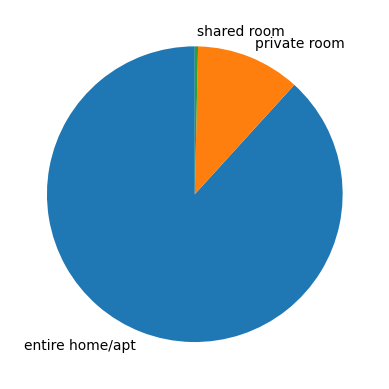

In [21]:
# The FIRST part of the project
# Sub-question 1.1
# For the year 2019
print("Output of the 1.1 sub-question for the year 2019:\n")
temp = result_df2_2019["room_type"].value_counts()
common_room_type_2019 = temp.sort_values(ascending=False).head()
print(common_room_type_2019)

common_room_type_2019.plot(kind='pie', ylabel='',startangle=90)

Output of the 1.1 sub-question for the year 2023:

room_type
entire home/apt    32564
private room        3085
hotel room           349
shared room          144
Name: count, dtype: int64


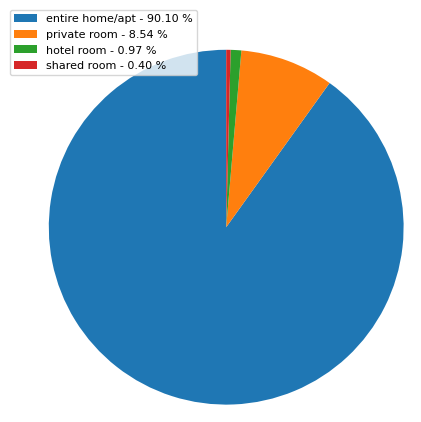

In [22]:
# For the year 2023
print("Output of the 1.1 sub-question for the year 2023:\n")
temp = result_df2_2023["room_type"].value_counts()
common_room_type_2023 = temp.sort_values(ascending=False).head()
print(common_room_type_2023)

index_list = common_room_type_2023.index.tolist()
values_list = common_room_type_2023.tolist()

x = np.char.array(index_list)
y = np.array(values_list)
porcent = 100.*y/y.sum()

patches, texts = plt.pie(y, startangle=90, radius=1.2)
labels = ['{0} - {1:1.2f} %'.format(i,j) for i,j in zip(x, porcent)]

sort_legend = True
if sort_legend:
    patches, labels, dummy =  zip(*sorted(zip(patches, labels, y),
                                          key=lambda x: x[2],
                                          reverse=True))

plt.legend(patches, labels, loc='center left', bbox_to_anchor=(-0.1, 1.), fontsize=8)

plt.savefig('piechart.png', bbox_inches='tight')

Output of the 1.2 sub-question for the year 2019:

              price
month              
april     61.339358
february  61.758200
march     61.388883


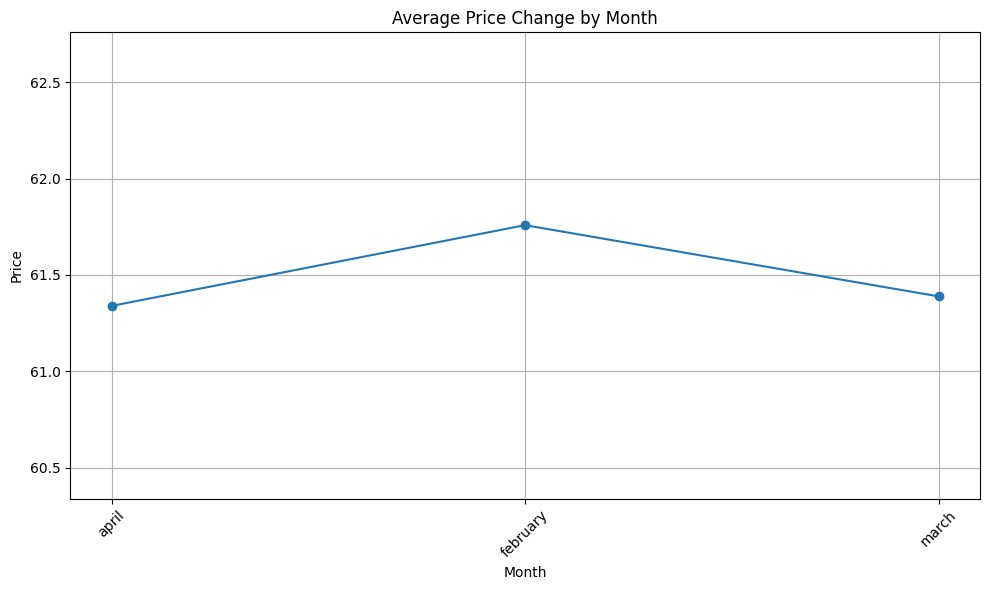




Output of the 1.2 sub-question for the year 2023:

                price
month                
june       103.708926
march       88.504012
september  100.080417


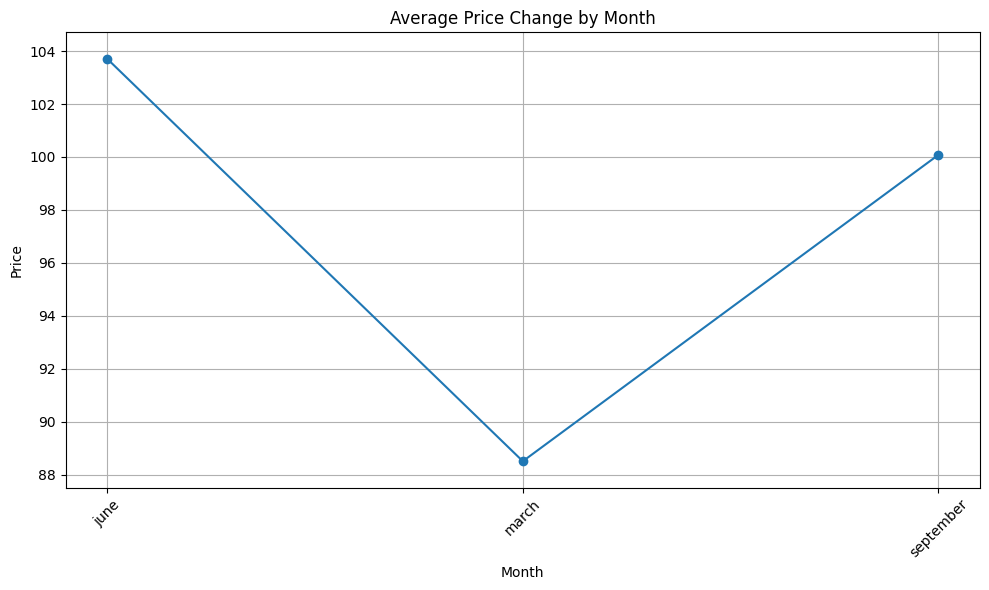

In [23]:
# Sub-question 1.2
def chart_function_for_the_question_1_2(mean_month_year):
  plt.figure(figsize=(10, 6))
  plt.plot(mean_month_year.index, mean_month_year["price"], marker="o")  # Line plot with markers
  plt.title("Average Price Change by Month")
  plt.xlabel("Month")
  plt.ylabel("Price")
  plt.xticks(rotation=45)  # Rotate month names for better visibility
  plt.grid(True)
  plt.tight_layout()  # Adjust layout to make room for the rotated month labels
  plt.ylim(mean_month_year.price.min() - 1, mean_month_year.price.max() + 1)
  plt.show()


# For the year 2019
print("Output of the 1.2 sub-question for the year 2019:\n")
mean_month_2019 = result_df2_2019[["month", "price"]].groupby("month").mean()
print(mean_month_2019)
chart_function_for_the_question_1_2(mean_month_2019)
print("\n\n")

# For the year 2023
print("Output of the 1.2 sub-question for the year 2023:\n")
mean_month_2023 = result_df2_2023[["month", "price"]].groupby("month").mean()
print(mean_month_2023)
chart_function_for_the_question_1_2(mean_month_2023)

In [24]:
def plotly_pie_chart_function(index_list, temp_list):
  fig = go.Figure(data=[go.Pie(labels=index_list, values=temp_list)])

  fig.update_traces(hoverinfo='label+percent', textinfo='value', textfont_size=20,
                  marker=dict(colors=colors, line=dict(color='#000000', width=2)))
  fig.show()

In [25]:
# Sub-question 1.3
def function_for_question_1_3(df, year):
  print("Output of the 1.3 sub-question for the year " + str(year) + ":\n")
  temp = df[["neighbourhood", "number_of_reviews"]].groupby('neighbourhood').sum()
  neighbourhood_reviews = temp.sort_values(ascending = False, by=["number_of_reviews"]).head()

  index_list = neighbourhood_reviews.index.tolist()
  # print(index_list)
  # print("-----------------------------------")
  print(neighbourhood_reviews)
  # print("-----------------------------------")
  column_number_of_reviews_list = neighbourhood_reviews["number_of_reviews"].tolist()
  # print(column_number_of_reviews_list)
  plotly_pie_chart_function(index_list, column_number_of_reviews_list)

# For the year 2019
function_for_question_1_3(result_df2_2019, 2019)
print("\n\n")
# For the year 2023
function_for_question_1_3(result_df2_2023, 2023)

Output of the 1.3 sub-question for the year 2019:

               number_of_reviews
neighbourhood                   
plaka                     132139
koukaki                    90307
neos kosmos                82637
psyri                      54297
metaxourgeio               43228





Output of the 1.3 sub-question for the year 2023:

                                  number_of_reviews
neighbourhood                                      
εμπορικο τριγωνο-πλακα                       430734
κουκακι-μακρυγιαννη                          206115
νεος κοσμος                                  128490
μουσειο-εξαρχεια-νεαπολη                     103026
αγιος κωνσταντινος-πλατεια βαθης             101893


In [26]:
# Sub-question 1.4
def function_for_question_1_4(df, year):
  print("Output of the 1.4 sub-question for the year " + str(year) + ":\n")
  temp = df['neighbourhood'].value_counts()
  real_estate = temp.sort_values(ascending=False).head()
  print(real_estate)
  index_list = real_estate.index.tolist()
  # print("-------------------------------------------------")
  # print(index_list)
  # print("-------------------------------------------------")
  # print(real_estate.tolist())
  plotly_pie_chart_function(index_list, real_estate.tolist())


# For the year 2019
function_for_question_1_4(result_df2_2019, 2019)
print("\n\n")
# For the year 2023
function_for_question_1_4(result_df2_2023, 2023)

Output of the 1.4 sub-question for the year 2019:

neighbourhood
plaka          3135
neos kosmos    2351
koukaki        2303
kolonaki       1712
pangrati       1694
Name: count, dtype: int64





Output of the 1.4 sub-question for the year 2023:

neighbourhood
εμπορικο τριγωνο-πλακα              6862
κουκακι-μακρυγιαννη                 3184
νεος κοσμος                         2725
μουσειο-εξαρχεια-νεαπολη            2714
αγιος κωνσταντινος-πλατεια βαθης    2251
Name: count, dtype: int64


In [27]:
# Sub-question 1.5
def Grouped_Bar_Chart_plotly_function(neighbourhood_name_list, neighbourhood_month_entries, month1, month2 , month3):
  fig = go.Figure(data=
   [go.Bar(name=month1.title(), x=neighbourhood_name_list, y=neighbourhood_month_entries[neighbourhood_month_entries["month"] == month1]["size"].tolist()),
    go.Bar(name=month2.title(), x=neighbourhood_name_list, y=neighbourhood_month_entries[neighbourhood_month_entries["month"] == month2]["size"].tolist()),
    go.Bar(name=month3.title(), x=neighbourhood_name_list, y=neighbourhood_month_entries[neighbourhood_month_entries["month"] == month3]["size"].tolist())])
  fig.update_layout(barmode='group')
  fig.update_layout(xaxis = go.layout.XAxis(tickangle = 90))
  fig.show()


def function_for_question_1_5(df, year):
  print("Output of the 1.5 sub-question for the year " + str(year) + ":\n")
  neighbourhood_month_entries = df.groupby(["neighbourhood","month"], as_index=False).size()
  print(neighbourhood_month_entries)

  # print("----------------------------------------")
  neighbourhood_names = neighbourhood_month_entries["neighbourhood"].drop_duplicates()
  # print(neighbourhood_names)

  neighbourhood_name_list = neighbourhood_names.tolist()
  # print(neighbourhood_name_list)
  if year == 2019:
    Grouped_Bar_Chart_plotly_function(neighbourhood_name_list, neighbourhood_month_entries, "february", "march", "april")
  else:
    Grouped_Bar_Chart_plotly_function(neighbourhood_name_list, neighbourhood_month_entries, 'march', 'june', 'september')


# For the year 2019
function_for_question_1_5(result_df2_2019, 2019)
print("\n\n")
# For the year 2023
function_for_question_1_5(result_df2_2023, 2023)

Output of the 1.5 sub-question for the year 2019:

     neighbourhood     month  size
0     agios loukas     april    70
1     agios loukas  february    67
2     agios loukas     march    69
3   agios nikolaos     april   206
4   agios nikolaos  february   193
..             ...       ...   ...
94         thiseio  february   312
95         thiseio     march    92
96       votanikos     april    59
97       votanikos  february    50
98       votanikos     march    54

[99 rows x 3 columns]





Output of the 1.5 sub-question for the year 2023:

        neighbourhood      month  size
0      1ο νεκροταφειο       june    51
1      1ο νεκροταφειο      march    44
2      1ο νεκροταφειο  september    55
3    αγιος ελευθεριος       june    26
4    αγιος ελευθεριος      march    27
..                ...        ...   ...
127            σταδιο      march   212
128            σταδιο  september   247
129   σταθμος λαρισης       june    83
130   σταθμος λαρισης      march    74
131   σταθμος λαρισης  september    80

[132 rows x 3 columns]


Output of the 1.6 sub-question for the year 2019:

neighbourhood
plaka                3135
neos kosmos          2351
koukaki              2303
kolonaki             1712
pangrati             1694
larissis             1569
metaxourgeio         1510
ambelokipi           1465
psyri                1428
exarcheia            1320
pedion areos          836
mets                  830
kypseli               787
attiki                755
kerameikos            753
neapoli               698
petralona             693
patisia               666
agios nikolaos        602
thiseio               515
ilisia                499
kolonos               366
gazi                  281
no data               258
agios loukas          206
votanikos             163
akadimia platonos     113
sepolia                97
goudi                  87
monastiraki            80
rizoupoli              55
profitis daniil        39
rouf                   12
Name: count, dtype: int64


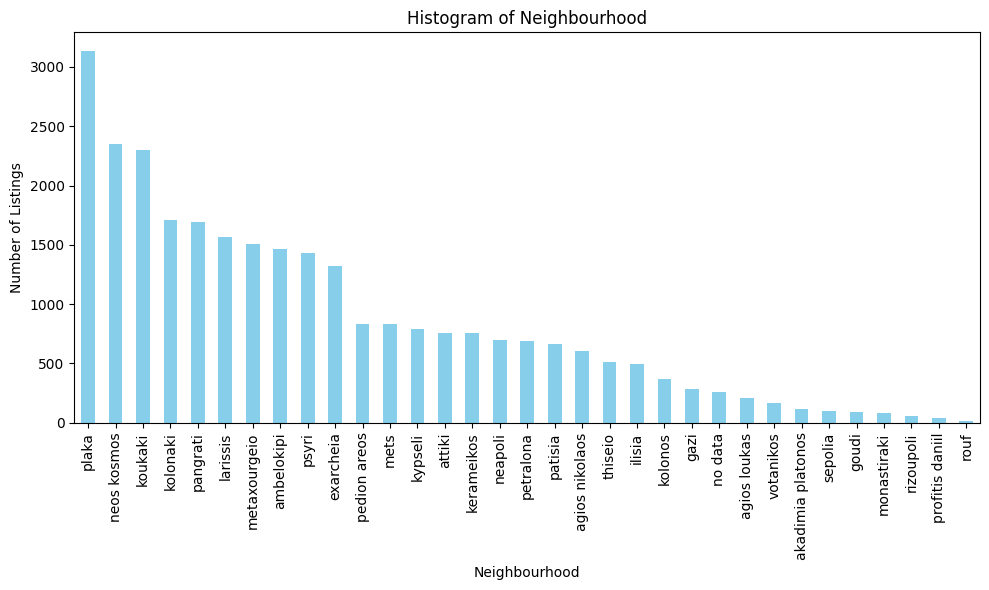




Output of the 1.6 sub-question for the year 2023:

neighbourhood
εμπορικο τριγωνο-πλακα              6862
κουκακι-μακρυγιαννη                 3184
νεος κοσμος                         2725
μουσειο-εξαρχεια-νεαπολη            2714
αγιος κωνσταντινος-πλατεια βαθης    2251
πλατεια αττικης                     1592
παγκρατι                            1416
αμπελοκηποι                         1210
κολωνακι                            1203
ακροπολη                            1088
θησειο                              1085
πετραλωνα                           1009
κεραμεικος                           988
κυψελη                               753
σταδιο                               698
γουδι                                648
ιλισια                               613
πλατεια αμερικης                     468
ζαππειο                              466
λυκαβηττος                           459
πατησια                              458
νιρβανα                              452
ανω κυψελη                    

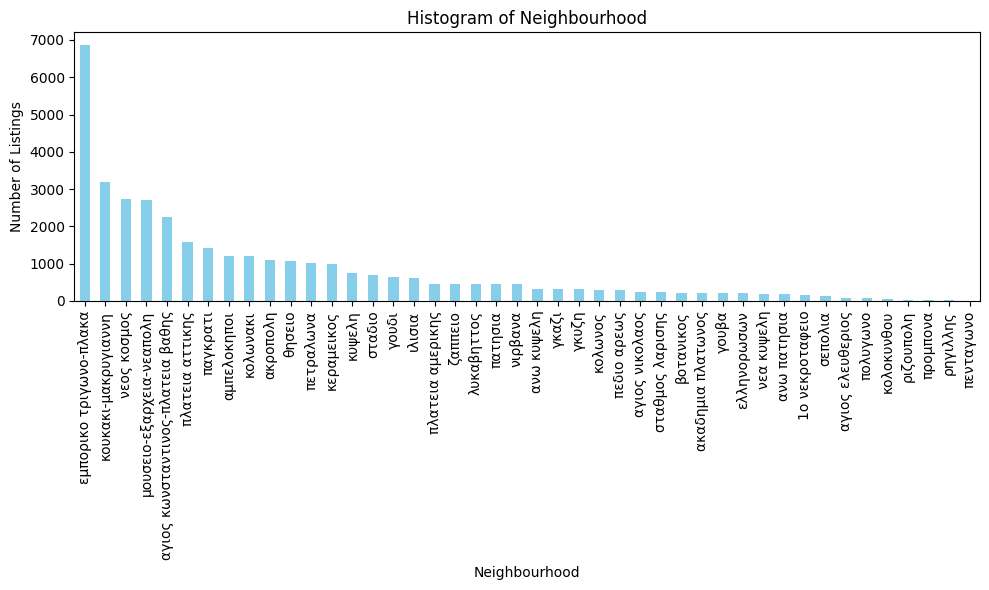

In [28]:
# Sub-question 1.6
def histogram_function_question_1_6(neighbourhood):
  neighbourhood.plot(kind='bar', figsize=(10, 6), color='skyblue')

  # Adding titles and labels
  plt.title('Histogram of Neighbourhood')
  plt.xlabel('Neighbourhood')
  plt.ylabel('Number of Listings')
  plt.xticks(rotation=90)  # Rotate the x-axis labels for readability
  plt.tight_layout()  # Adjust the layout
  plt.show()

# For the year 2019
print("Output of the 1.6 sub-question for the year 2019:\n")
neighbourhood_2019 = result_df2_2019['neighbourhood'].value_counts()
print(neighbourhood_2019)
histogram_function_question_1_6(neighbourhood_2019)

print("\n\n")
# For the year 2023
print("Output of the 1.6 sub-question for the year 2023:\n")
neighbourhood_2023 = result_df2_2023['neighbourhood'].value_counts()
print(neighbourhood_2023)
histogram_function_question_1_6(neighbourhood_2023)

In [29]:
# Sub-question 1.7
# For the year 2019
print("Output of the 1.7 sub-question for the year 2019:\n")
temp = result_df2_2019.groupby('neighbourhood')["room_type"].value_counts().reset_index()
temp.sort_values(by=['neighbourhood', 'count'], ascending=[True, False], inplace=True)
most_frequent_room_type_by_neighbourhood_2019 = temp.drop_duplicates(subset='neighbourhood')
most_frequent_room_type_by_neighbourhood_2019

Output of the 1.7 sub-question for the year 2019:



,neighbourhood,room_type,count
0,agios loukas,entire home/apt,174
3,agios nikolaos,entire home/apt,518
5,akadimia platonos,entire home/apt,92
7,ambelokipi,entire home/apt,1369
10,attiki,entire home/apt,644
12,exarcheia,entire home/apt,1164
14,gazi,entire home/apt,239
17,goudi,entire home/apt,63
20,ilisia,entire home/apt,470
22,kerameikos,entire home/apt,681


In [30]:
# For the year 2023
print("Output of the 1.7 sub-question for the year 2023:\n")
temp = result_df2_2023.groupby('neighbourhood')["room_type"].value_counts().reset_index()
temp.sort_values(by=['neighbourhood', 'count'], ascending=[True, False], inplace=True)
most_frequent_room_type_by_neighbourhood_2023 = temp.drop_duplicates(subset='neighbourhood')
most_frequent_room_type_by_neighbourhood_2023

Output of the 1.7 sub-question for the year 2023:



,neighbourhood,room_type,count
0,1ο νεκροταφειο,entire home/apt,150
1,αγιος ελευθεριος,entire home/apt,86
2,αγιος κωνσταντινος-πλατεια βαθης,entire home/apt,1903
5,αγιος νικολαος,entire home/apt,228
7,ακαδημια πλατωνος,entire home/apt,204
9,ακροπολη,entire home/apt,1012
12,αμπελοκηποι,entire home/apt,1161
15,ανω κυψελη,entire home/apt,285
17,ανω πατησια,entire home/apt,171
19,βοτανικος,entire home/apt,193


In [31]:
# Sub-question 1.8
def function_for_question_1_8(df, year):
  print("Output of the 1.8 sub-question for the year " + str(year) + ":")
  avg_price_per_room_type = df.groupby('room_type')['price'].mean()
  avg_price_per_room_type = avg_price_per_room_type.sort_values(ascending=False)
  print(avg_price_per_room_type.index[0])
  print("\n")

  print(avg_price_per_room_type)

  room_types_list = avg_price_per_room_type.index.tolist()
  # print("-------------------------------------------------")
  # print(room_types_list)
  # print("-------------------------------------------------")
  # print(avg_price_per_room_type.tolist())
  plotly_pie_chart_function(room_types_list, avg_price_per_room_type.tolist())


# For the year 2019
function_for_question_1_8(result_df2_2019, 2019)
print("\n\n")
# For the year 2023
function_for_question_1_8(result_df2_2023, 2023)

Output of the 1.8 sub-question for the year 2019:
entire home/apt


room_type
entire home/apt    62.490692
private room       54.508181
shared room        37.091837
Name: price, dtype: float64





Output of the 1.8 sub-question for the year 2023:
hotel room


room_type
hotel room         217.074499
private room       104.354295
entire home/apt     96.104870
shared room         28.604167
Name: price, dtype: float64


In [45]:
# Sub-question 1.9
import folium

def create_map(df):
    m = folium.Map(location=[df.iloc[0]['latitude'], df.iloc[0]['longitude']], zoom_start=12)

    for index, row in df.iterrows():
        popup_info = f"Name: {row['name']}<br>Room Type: {row['room_type']}<br>Price: {row['price']}<br>Bedrooms: {row['bedrooms']}"
        popup = folium.Popup(popup_info, max_width=300)

        folium.Marker(
            location=[row['latitude'], row['longitude']],
            popup=popup,
            icon=folium.Icon(icon='info-sign')
        ).add_to(m)

    return m

# For the year 2019
print("Output of the 1.9 sub-question for the year 2019:")
map_df_2019 = create_map(result_df2_2019[result_df2_2019["month"] == "april"])
map_df_2019.save('map_2019.html')
map_df_2019

Output hidden; open in https://colab.research.google.com to view.

In [46]:
# For the year 2023
print("Output of the 1.9 sub-question for the year 2023:")
map_df_2023 = create_map(result_df2_2023[result_df2_2023["month"] == "september"])
map_df_2023.save('map_2023.html')
map_df_2023

Output hidden; open in https://colab.research.google.com to view.

Output of the 1.10 sub-question for the year 2019:


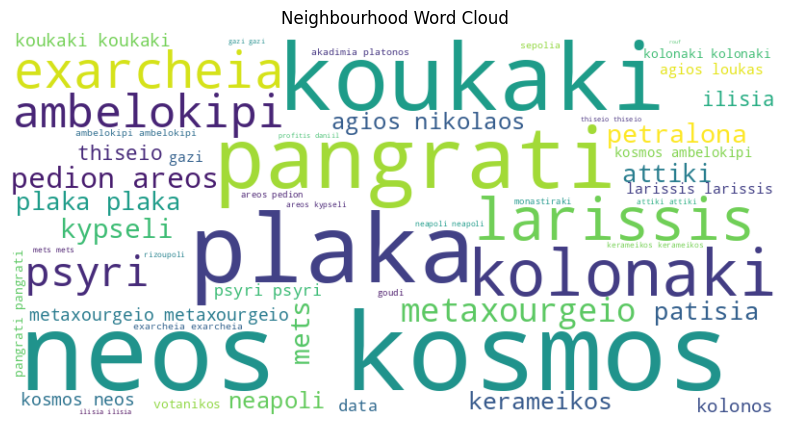

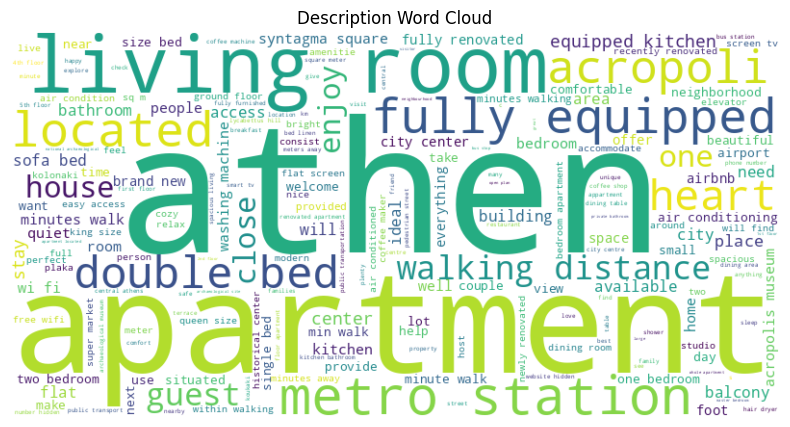

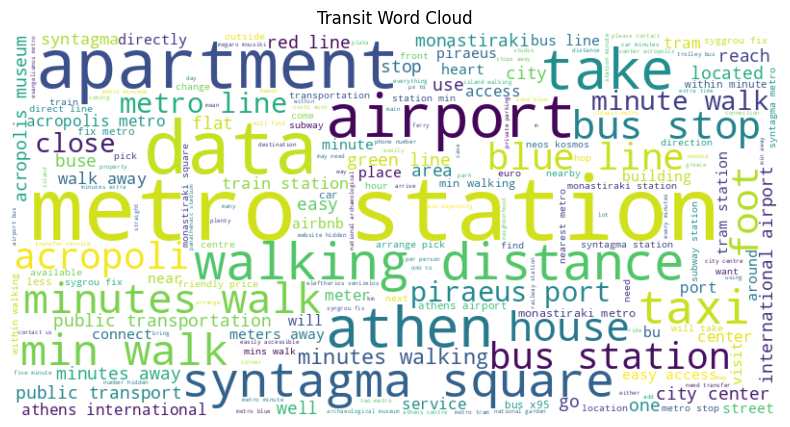

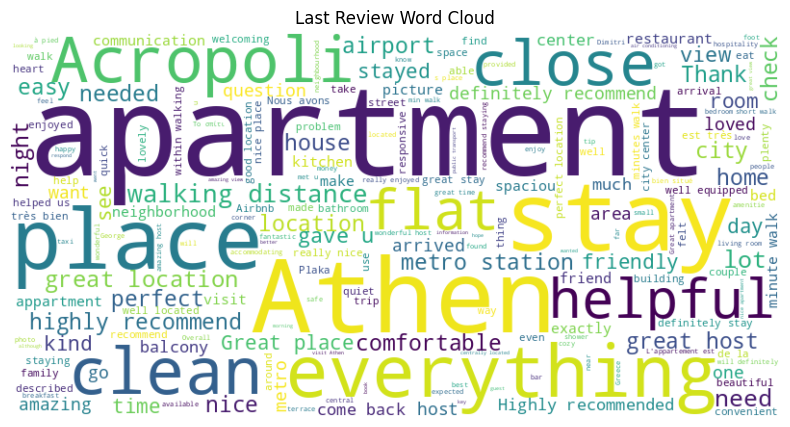

In [34]:
# Sub-question 1.10
from wordcloud import WordCloud

def generate_word_cloud(text_data, title):
    # Create a word cloud object
    wordcloud = WordCloud(width = 800, height = 400, background_color ='white').generate(text_data)

    # Display the word cloud
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis("off")
    plt.title(title)
    plt.show()

def function_for_question_1_10(df, year):
  print("Output of the 1.10 sub-question for the year " + str(year) + ":")

  neighbourhood_text = ' '.join(df['neighbourhood'].dropna().astype(str))
  generate_word_cloud(neighbourhood_text, 'Neighbourhood Word Cloud')
  print("\n\n")

  description_text = ' '.join(df['description'].dropna().astype(str))
  generate_word_cloud(description_text, 'Description Word Cloud')
  print("\n\n")

  if year == 2019:
    transit_text = ' '.join(df['transit'].dropna().astype(str))
    generate_word_cloud(transit_text, 'Transit Word Cloud')
    print("\n\n")

    dataset_february = pd.read_csv('/content/drive/MyDrive/dataset_tede/data/2019/febrouary/reviews.csv', low_memory=False)
    df_february_comments = dataset_february["comments"]

    dataset_april = pd.read_csv('/content/drive/MyDrive/dataset_tede/data/2019/april/reviews.csv', low_memory=False)
    df_april_comments = dataset_april["comments"]

    dataset_march = pd.read_csv('/content/drive/MyDrive/dataset_tede/data/2019/march/reviews.csv', low_memory=False)
    df_march_comments = dataset_march["comments"]

    df_comments = pd.concat([df_february_comments, df_april_comments, df_march_comments])
  else:
    dataset_june = pd.read_csv('/content/drive/MyDrive/dataset_tede/data/2023/june/reviews.csv', low_memory=False)
    df_june_comments = dataset_june["comments"]

    dataset_september = pd.read_csv('/content/drive/MyDrive/dataset_tede/data/2023/september/reviews.csv', low_memory=False)
    df_september_comments = dataset_september["comments"]

    df_comments = pd.concat([df_june_comments, df_september_comments])

  last_review_text = ' '.join(df_comments.dropna().astype(str))
  generate_word_cloud(last_review_text, 'Last Review Word Cloud')


# For the year 2019
function_for_question_1_10(result_df2_2019, 2019)

Output of the 1.10 sub-question for the year 2023:


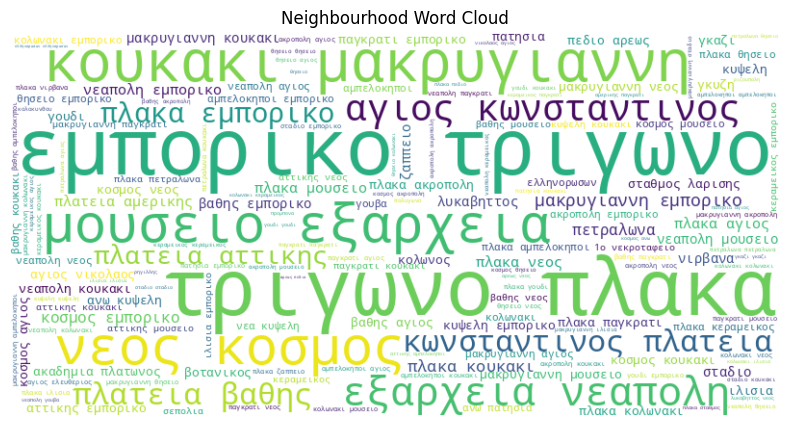

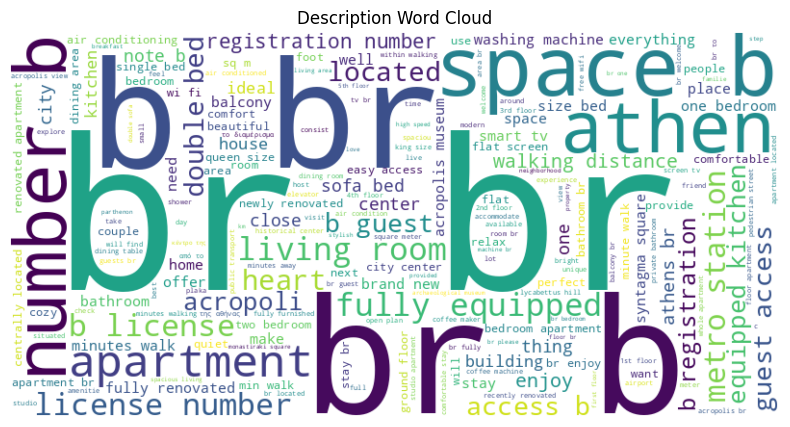

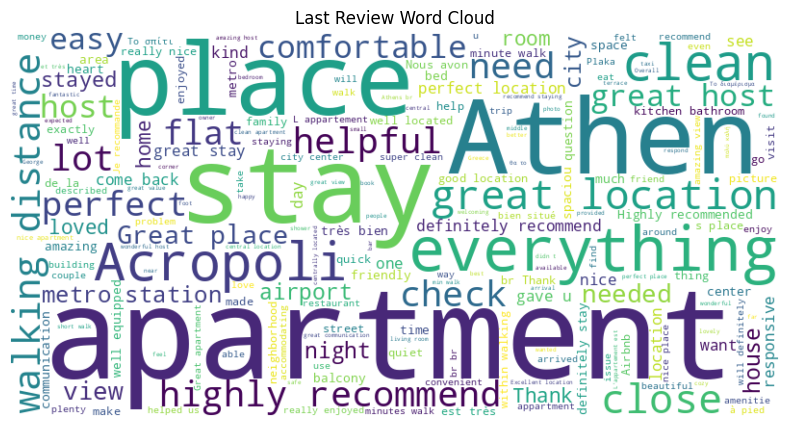

In [35]:
# For the year 2023
function_for_question_1_10(result_df2_2023, 2023)

Output of the 1.11 sub-question for the year 2019:


<ipython-input-36-d0ab47141ee6>:91: UserWarning:

[W007] The model you're using has no word vectors loaded, so the result of the Doc.similarity method will be based on the tagger, parser and NER, which may not give useful similarity judgements. This may happen if you're using one of the small models, e.g. `en_core_web_sm`, which don't ship with word vectors and only use context-sensitive tensors. You can always add your own word vectors, or use one of the larger models instead if available.

<ipython-input-36-d0ab47141ee6>:91: UserWarning:

[W008] Evaluating Doc.similarity based on empty vectors.



kitchen         147100
accesibility    130162
security        105933
bathroom        103884
technology       91799
services         51668
kids             41927
other            23532
facilities       15160
Name: count, dtype: int64


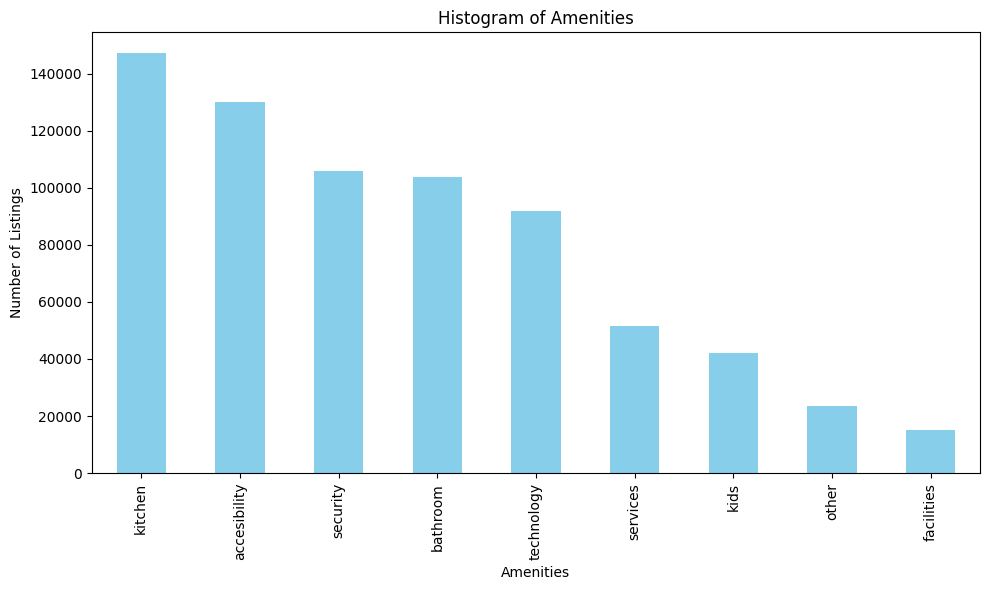

In [36]:
# Sub-question 1.11
import spacy

def histogram_function_question_1_11(temp):
  temp.plot(kind='bar', figsize=(10, 6), color='skyblue')

  # Adding titles and labels
  plt.title('Histogram of Amenities')
  plt.xlabel('Amenities')
  plt.ylabel('Number of Listings')
  plt.xticks(rotation=90)  # Rotate the x-axis labels for readability
  plt.tight_layout()  # Adjust the layout
  plt.show()

def categorise(amenities, similarities, main_amenities):

  amenities = amenities.replace('"', '')
  categories = []
  amenities_list = amenities[1:-1].split(",")

  # For every word/sentence from the list amenities_list we will find the most similar word from the list main_amenities
  for amenity in amenities_list:

      max = -1.0
      category = " "
      for i in range(0, len(main_amenities)):
        if similarities[amenity, main_amenities[i]] > max:
          max = similarities[amenity, main_amenities[i]]
          category = main_amenities[i]
      if max > 0.30:
        categories.append(category)
      # if for this word/sentence we didnt find any good similar word from the list main_amenities put it in the category other
      else:
        categories.append("other")

  # return the list which have replace every word/sentence for this row
  return categories

def function_for_question_1_11(temp_df, year):

  print("Output of the 1.11 sub-question for the year " + str(year) + ":")

  # Load English core nlp model
  nlp = spacy.load("en_core_web_sm")

  df = temp_df.copy()

  main_amenities =  ["kitchen", "bathroom", "accesibility", "technology", "facilities", "kids", "security", "services"]

  main_amenities_nlp = []
  for amenity in main_amenities:
    main_amenities_nlp.append(nlp(amenity))


  # List that has all the values of the column amenities for this dataframe
  rows = df["amenities"].values.tolist()

  # #------------------------------------------------------------------------------
  # f = open("rows.txt", "w")
  # for item in rows:
  #   f.write("%s\n" % item)

  # f.close()
  # #-----------------------------------------------------------------------------

  # Set that it will have all the different words/sentences that apperar on the column amenities of this dataset
  amenities = set()

  for row in rows:
    row = row.replace('"', '')[1:-1].split(",")
  # print(row)
    # f = open("row.txt", "w")
    # f.write("%s\n" % row)
    # f.close()
    for amenity in row:
      amenities.add(amenity)

  # print(amenities)
  # print(len(amenities))

  # Dictionary that for every word/sentence from the set amenities and for all the words from the list main_amenities it
  # will store the number of how much similar these two things are (the closer to the number 1 the more similar these two
  # things are)
  similarities = {}
  for amenity in amenities:

    # print(amenity)
      amelity_nlp = nlp(amenity)

      for i in range(0, len(main_amenities)):
        similarity = main_amenities_nlp[i].similarity(amelity_nlp)
        similarities[amenity,main_amenities[i]] = similarity


  # print(similarities)
  #------------------------------------------------------------------------------
  # f = open("similarities.txt", "w")
  # f.write("%s\n" % similarities)
  # f.close()
  # -----------------------------------------------------------------------------

  # And now we create a new column amenities2 that will replace every word/sentence for every row from the column
  # amenities with the most similar word from the list main_amenities
  df["amenities2"] = df.apply(lambda x: categorise(x.amenities, similarities, main_amenities), axis=1)
  # ------------------------------------------------------------------------------

  flattened_amenities = [
      amenity
      for sublist in df['amenities2']
      if isinstance(sublist, list)  # Check if the item is a list
      for amenity in sublist
  ]
  print(pd.Series(flattened_amenities).value_counts())



  histogram_function_question_1_11(pd.Series(flattened_amenities).value_counts())


  # f = open("ena.txt", "w")
  # rows1 = df["amenities"].values.tolist()
  # rows2 = df["amenities2"].values.tolist()
  # # rows = df["amenities"].values.tolist()
  # for item1, item2 in zip(rows1, rows2):
  #   f.write("%s\n" % item1)
  #   f.write("\n")
  #   f.write("%s\n" % item2)


  # f.close()
  #--------------------------------------------------------------------------------

# For the year 2019
function_for_question_1_11(result_df2_2019, 2019)

Output of the 1.11 sub-question for the year 2023:


<ipython-input-36-d0ab47141ee6>:91: UserWarning:

[W007] The model you're using has no word vectors loaded, so the result of the Doc.similarity method will be based on the tagger, parser and NER, which may not give useful similarity judgements. This may happen if you're using one of the small models, e.g. `en_core_web_sm`, which don't ship with word vectors and only use context-sensitive tensors. You can always add your own word vectors, or use one of the larger models instead if available.

<ipython-input-36-d0ab47141ee6>:91: UserWarning:

[W008] Evaluating Doc.similarity based on empty vectors.



other           373114
accesibility    294170
kitchen         211147
security        147615
technology       71376
bathroom         31738
kids             13846
services         11974
facilities         237
Name: count, dtype: int64


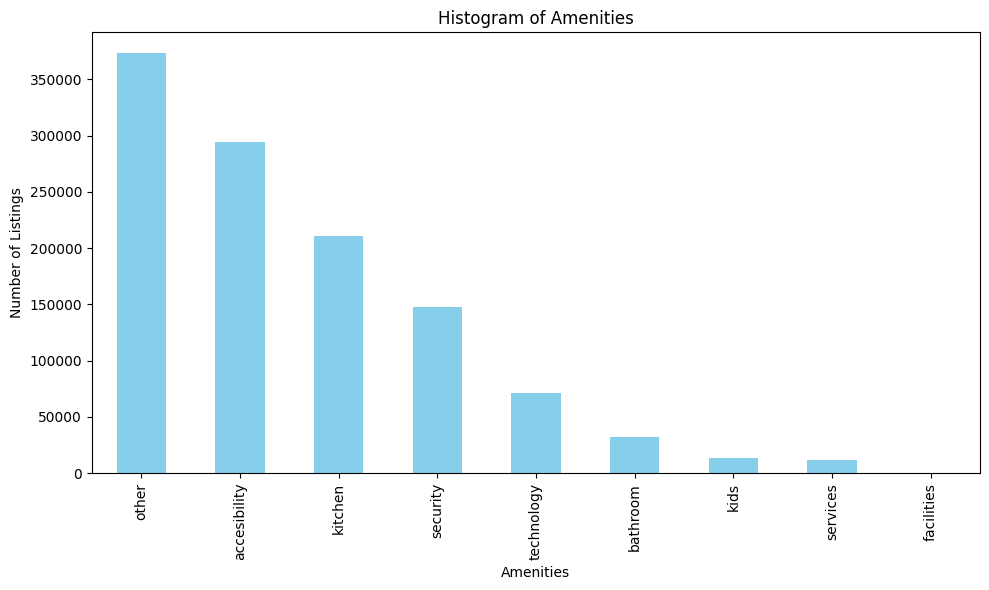

In [37]:
# For the year 2023
function_for_question_1_11(result_df2_2023, 2023)

Output of the 1.12 sub-question for the year 2019:



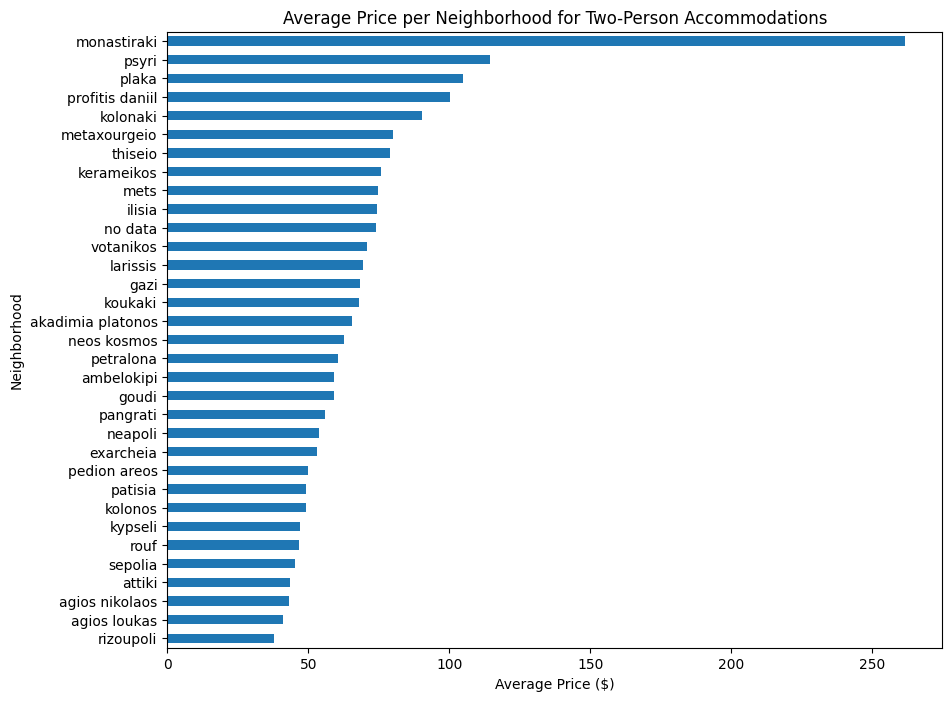

neighbourhood
rizoupoli                Economical
agios loukas             Economical
agios nikolaos           Economical
attiki                   Economical
sepolia                  Economical
rouf                     Economical
kypseli                  Economical
kolonos                  Economical
patisia                  Economical
pedion areos             Economical
exarcheia                Economical
neapoli                    Moderate
pangrati                   Moderate
goudi                      Moderate
ambelokipi                 Moderate
petralona                  Moderate
neos kosmos                Moderate
akadimia platonos          Moderate
koukaki                    Moderate
gazi                       Moderate
larissis                   Moderate
votanikos                  Moderate
no data              Very Expensive
ilisia               Very Expensive
mets                 Very Expensive
kerameikos           Very Expensive
thiseio              Very Expensive
metaxourgeio  

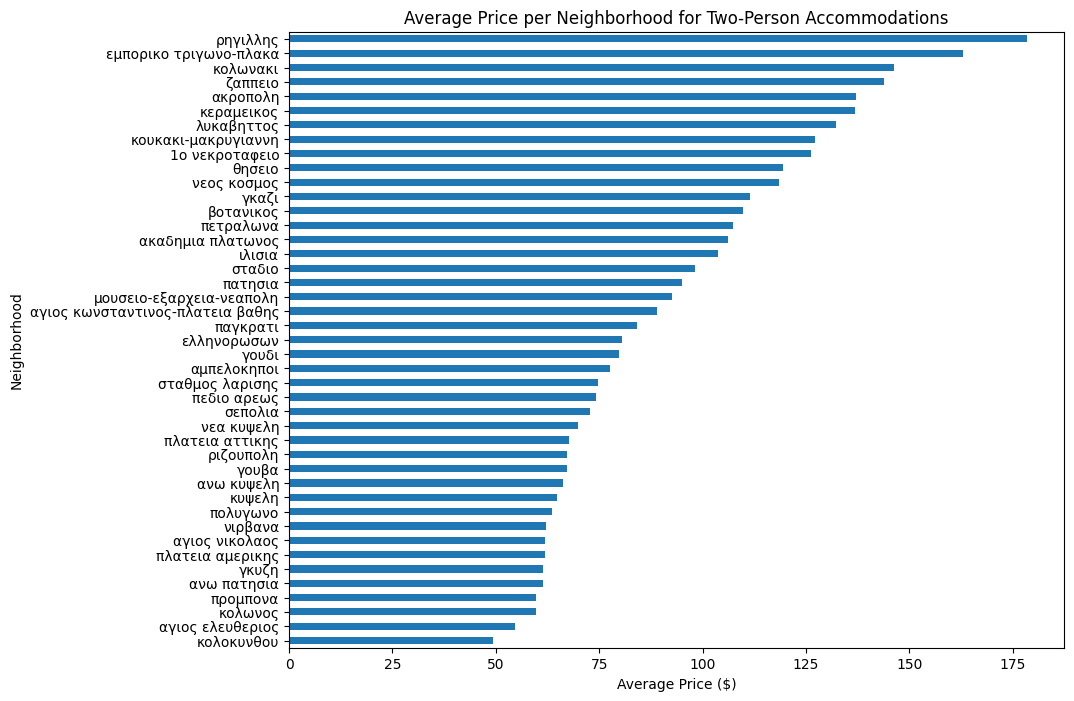

neighbourhood
κολοκυνθου                              Economical
αγιος ελευθεριος                        Economical
κολωνος                                 Economical
προμπονα                                Economical
ανω πατησια                             Economical
γκυζη                                   Economical
πλατεια αμερικης                        Economical
αγιος νικολαος                          Economical
νιρβανα                                 Economical
πολυγωνο                                Economical
κυψελη                                  Economical
ανω κυψελη                              Economical
γουβα                                   Economical
ριζουπολη                               Economical
πλατεια αττικης                           Moderate
νεα κυψελη                                Moderate
σεπολια                                   Moderate
πεδιο αρεως                               Moderate
σταθμος λαρισης                           Moderate
αμπελοκηποι      

In [38]:
# Sub-question 1.12
def function_for_question_1_12(df, year):

  print("Output of the 1.12 sub-question for the year " + str(year) + ":\n")

  two_bedrooms = df[df["bedrooms"] == 2]

  avg_prices = two_bedrooms.groupby("neighbourhood")["price"].mean().sort_values()

  # it sets your limits
  quantiles = avg_prices.quantile([0.33, 0.66])

  # print(quantiles)

  # Plot average prices
  plt.figure(figsize=(10, 8))
  avg_prices.plot(kind='barh')
  plt.title('Average Price per Neighborhood for Two-Person Accommodations')
  plt.xlabel('Average Price ($)')
  plt.ylabel('Neighborhood')
  plt.show()

  def price_category(price):
      if price <= quantiles.iloc[0]:
          return 'Economical'
      elif price <= quantiles.iloc[1]:
          return 'Moderate'
      else:
          return 'Very Expensive'

  neighborhood_categories = avg_prices.apply(price_category)

  print(neighborhood_categories)



# For the year 2019
function_for_question_1_12(result_df2_2019, 2019)
print("\n\n")
# For the year 2023
function_for_question_1_12(result_df2_2023, 2023)

# **Sub-question 1.13**




1.   What is the relation between ratings and review frequency ?
        
          i.e. how the number of reviews a property has received relates to its rating. Properties with more reviews
          may be more popular or offer a better experience, leading to higher ratings.
2.   What is the distribution of property type (e.g., entire home/apt, private room ...) by neighborhood ?

          Examine how the property type differ in the various neighborhoods of Athens. This will show you which
          neighborhoods are more likely to have entire apartments for rent versus private rooms, reflecting different
          preferences or availability.

3.   How much has changed the price by neighbourhood for march 2019 to march 2023 ?

          This is an interesting question because it will show as how much the popularity of a neighbourhood has changed
          (mayde it has fallen or rise, mayde new neighbourhoods have appeared which previously didnt exist)








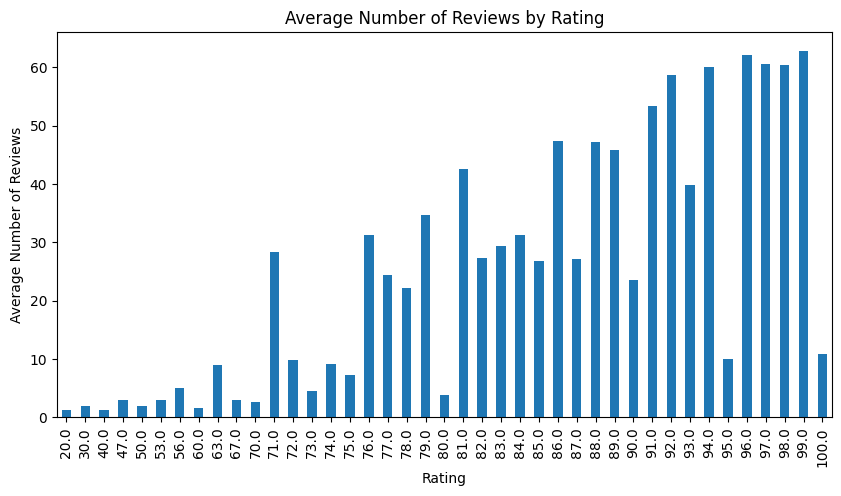

review_scores_rating
20.0      1.309524
30.0      2.000000
40.0      1.225000
47.0      3.000000
50.0      2.000000
53.0      3.000000
56.0      5.000000
60.0      1.596330
63.0      9.000000
67.0      3.000000
70.0      2.546875
71.0     28.333333
72.0      9.800000
73.0      4.434783
74.0      9.166667
75.0      7.190476
76.0     31.181818
77.0     24.375000
78.0     22.200000
79.0     34.750000
80.0      3.748454
81.0     42.617647
82.0     27.386364
83.0     29.333333
84.0     31.308411
85.0     26.791209
86.0     47.387755
87.0     27.205761
88.0     47.269710
89.0     45.902439
90.0     23.478138
91.0     53.405594
92.0     58.650089
93.0     39.848455
94.0     60.008092
95.0      9.972662
96.0     62.093870
97.0     60.641097
98.0     60.321834
99.0     62.877410
100.0    10.859316
Name: number_of_reviews, dtype: float64


In [39]:
# Sub-question 1.13
# 1) The relation between ratings and review frequency
review_analysis = result_df2_2019.groupby('review_scores_rating')['number_of_reviews'].mean()
plt.figure(figsize=(10, 5))
review_analysis.plot(kind='bar', title='Average Number of Reviews by Rating')
plt.ylabel('Average Number of Reviews')
plt.xlabel('Rating')
plt.show()
print(review_analysis)

For the year 2019 we have:



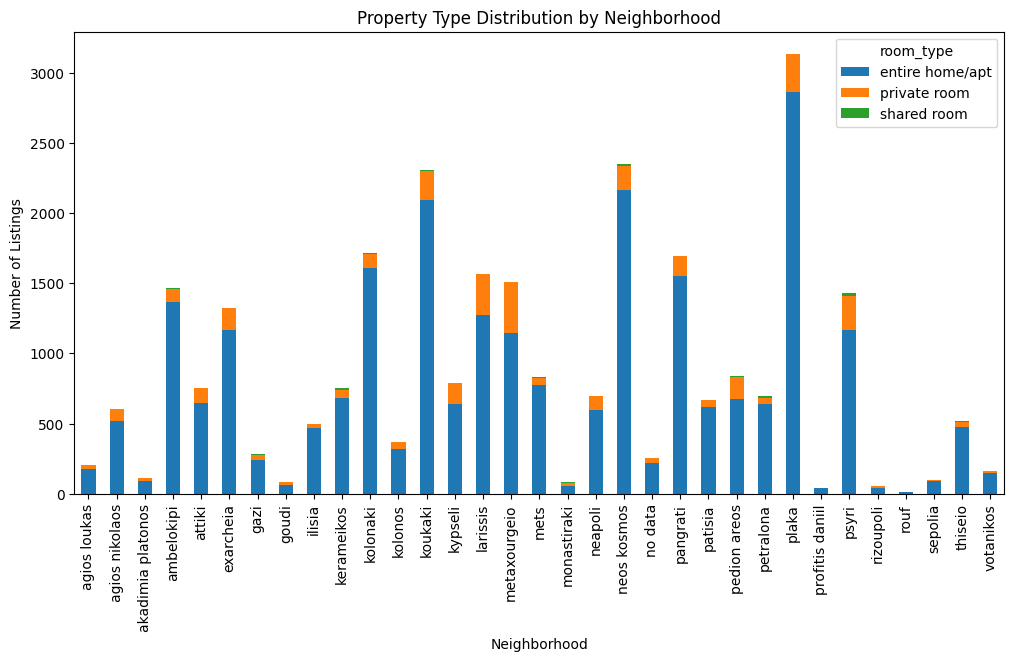



room_type          entire home/apt  private room  shared room
neighbourhood                                                
agios loukas                   174            29            3
agios nikolaos                 518            84            0
akadimia platonos               92            21            0
ambelokipi                    1369            92            4
attiki                         644           111            0
exarcheia                     1164           156            0
gazi                           239            35            7
goudi                           63            18            6
ilisia                         470            29            0
kerameikos                     681            58           14
kolonaki                      1605           106            1
kolonos                        321            45            0
koukaki                       2093           208            2
kypseli                        641           145            1
lariss

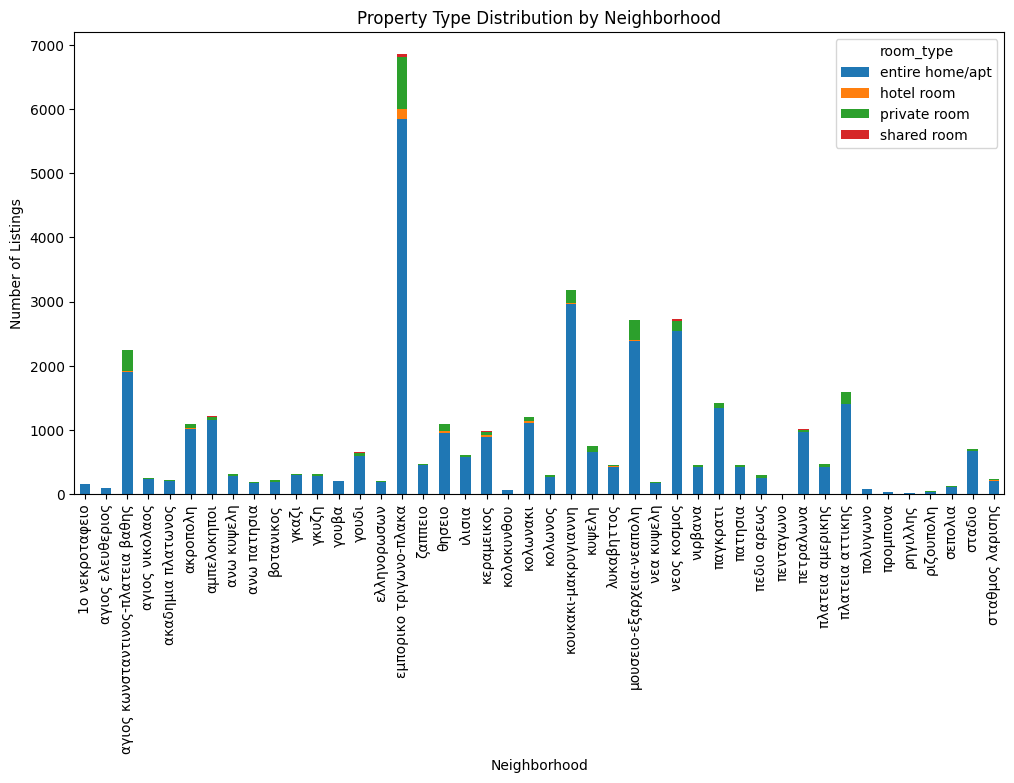



room_type                         entire home/apt  hotel room  private room  \
neighbourhood                                                                 
1ο νεκροταφειο                                150           0             0   
αγιος ελευθεριος                               86           0             0   
αγιος κωνσταντινος-πλατεια βαθης             1903          12           336   
αγιος νικολαος                                228           0            20   
ακαδημια πλατωνος                             204           0             7   
ακροπολη                                     1012          18            58   
αμπελοκηποι                                  1161           0            46   
ανω κυψελη                                    285           0            33   
ανω πατησια                                   171           0             9   
βοτανικος                                     193           0            23   
γκαζι                                         299 

In [40]:
# 2) Distribution of property type by neighborhood
def distribution_property_type_neighborhood(df, year):
  print("For the year " + str(year) + " we have:\n")
  property_types = pd.crosstab(df['neighbourhood'], df['room_type'])
  property_types.plot(kind='bar', stacked=True, figsize=(12, 6), title='Property Type Distribution by Neighborhood')
  plt.ylabel('Number of Listings')
  plt.xlabel('Neighborhood')
  plt.show()
  print("\n")
  print(property_types)


# For the year 2019
distribution_property_type_neighborhood(result_df2_2019, 2019)
print("\n\n")
# For the year 2023
distribution_property_type_neighborhood(result_df2_2023, 2023)

In [41]:
# 3) Price by neighbourhood for march 2019 to march 2023
df_march_2019 = result_df2_2019[result_df2_2019["month"] == "march"]
avg_price_per_neighbourhood_2019 = df_march_2019.groupby("neighbourhood")["price"].mean()

fig = go.Figure([go.Bar(x=avg_price_per_neighbourhood_2019.index.tolist(), y=avg_price_per_neighbourhood_2019.tolist())])
fig.update_layout(xaxis = go.layout.XAxis(tickangle = 90))
fig.update_layout(title={'text': "For the year 2019", 'y':0.9, 'x':0.5, 'xanchor': 'center', 'yanchor': 'top'})
fig.show()

df_march_2023 = result_df2_2023[result_df2_2023["month"] == "march"]
avg_price_per_neighbourhood_2023 = df_march_2023.groupby("neighbourhood")["price"].mean()

fig = go.Figure([go.Bar(x=avg_price_per_neighbourhood_2023.index.tolist(), y=avg_price_per_neighbourhood_2023.tolist())])
fig.update_layout(xaxis = go.layout.XAxis(tickangle = 90))
fig.update_layout(title={'text': "For the year 2023", 'y':0.9, 'x':0.5, 'xanchor': 'center', 'yanchor': 'top'})
fig.show()

# Comment: Because the column "neighbourhood" is not written in the same language I couldnt use grouped bar chart like as for the question 1.5,
# if the dataset for 2023 for the column "neighbourhood" was better written I would, netherless it is interesting even for these kind of data I had

print("\n\n")
print("Output for the year 2019:\n")
print(avg_price_per_neighbourhood_2019)
print("\n\n")
print("Output for the year 2023:\n")
print(avg_price_per_neighbourhood_2023)




Output for the year 2019:

neighbourhood
agios loukas          42.884058
agios nikolaos        34.640394
akadimia platonos     45.227273
ambelokipi            47.790323
attiki                36.972441
exarcheia             46.754310
gazi                  53.981818
goudi                 48.466667
ilisia                60.017544
kerameikos            65.913279
kolonaki              77.195540
kolonos               40.458333
koukaki               59.462141
kypseli               43.490260
larissis              52.466055
metaxourgeio          68.190291
mets                  60.981343
monastiraki           68.000000
neapoli               49.934343
neos kosmos           57.233716
no data              132.500000
pangrati              54.770833
patisia               39.117391
pedion areos          41.728625
petralona             46.550661
plaka                 96.550725
profitis daniil       74.200000
psyri                 90.613924
rizoupoli             34.666667
rouf                  42.750

Output of the 1.14 sub-question for the year 2019:
           num_host_listings
host_id                     
77457889                 124
29927830                  96
135482892                 86
748818                    80
1621474                   72
1418201                   63
112527018                 57
65714690                  48
149346682                 45
2089542                   45


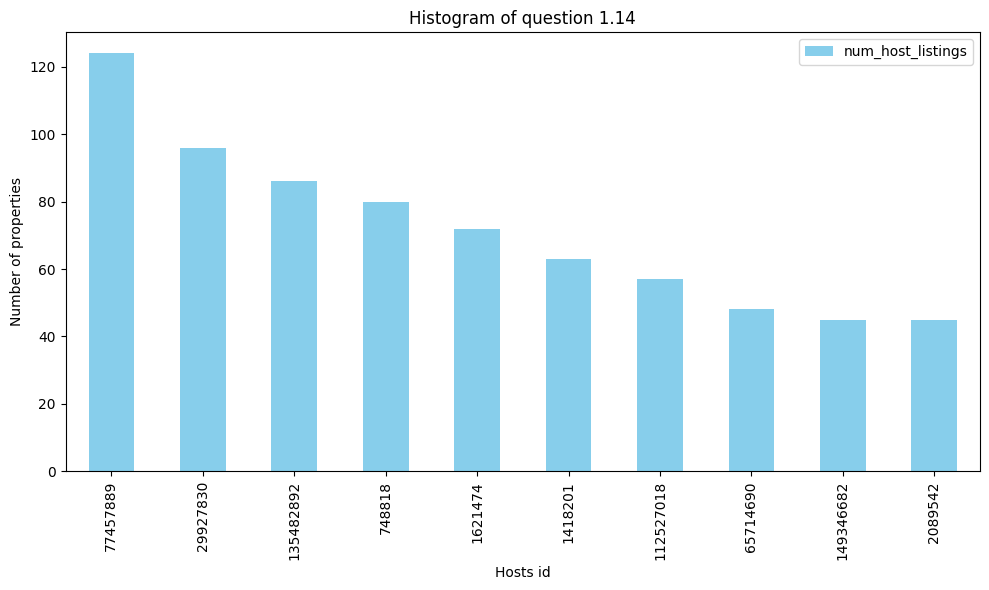




Output of the 1.14 sub-question for the year 2023:
           num_host_listings
host_id                     
20104194                 116
29927830                 115
113548208                 90
90390850                  89
748818                    76
182156346                 67
2089542                   62
47267002                  61
113353393                 60
123074489                 58


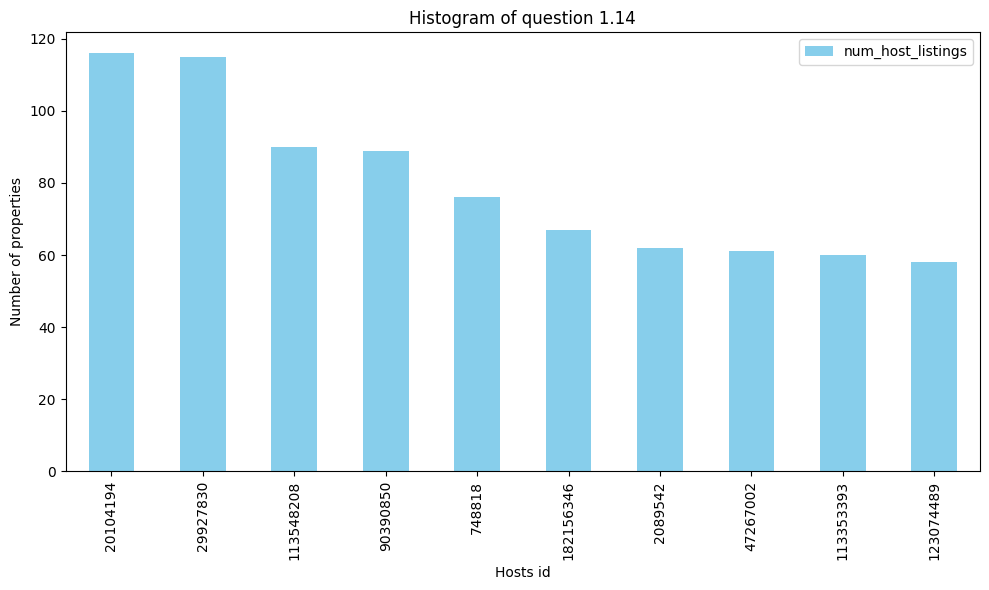

In [42]:
# Sub-question 1.14
def histogram_function_question_1_14(temp_df):
  temp_df.plot(kind='bar', figsize=(10, 6), color='skyblue')

  # Adding titles and labels
  plt.title('Histogram of question 1.14')
  plt.xlabel('Hosts id')
  plt.ylabel('Number of properties')
  plt.xticks(rotation=90)  # Rotate the x-axis labels for readability
  plt.tight_layout()  # Adjust the layout
  plt.show()

def function_for_question_1_14(df, year):
  print("Output of the 1.14 sub-question for the year " + str(year) + ":")
  host_listings_count = df.groupby('host_id')['id'].nunique().reset_index()
  host_listings_count.columns = ['host_id', 'num_host_listings']

  # Sort the data by the number of unique listings and retain the top 10 hosts
  top_hosts = host_listings_count.sort_values(by='num_host_listings', ascending=False).head(10)

  top_hosts.set_index('host_id', inplace=True)
  print(top_hosts)

  histogram_function_question_1_14(top_hosts)


# For the year 2019
function_for_question_1_14(result_df2_2019, 2019)
print("\n\n")
# For the year 2023
function_for_question_1_14(result_df2_2023, 2023)

# **Sub-question 1.15**

1.   Firstly the number of properties has increased, in 2019 it was 27878 while in 2023 it is 36142

2.   The most common room type remains the same i.e. the entire home/apt the only difference is that their number has increased, which is natural because of the 1.

3.   We see that in 2023 the average price has increased compared to 2019.    Additionally we notice that the most expensive month of 2019 february with an average price of about 62 dollars is smaller in relation to the cheapest month of 2023 march with an average price of about 88.5 dollars

4.   We notice that the first 4 positions of the neighborhoods with the most real estate registrations remain unchanged with the only difference being that the second has changed to the third, i.e. in 2019 we had the neos kosmos as second and the koukaki as the third, while in 2023 the koukaki came second and the neos kosmos came third the first and fourth positions remain the same. Also, the number has increased in all 4 of these neighborhoods which is natural because of the 1.

5.   We also notice that the more reviews a neighborhood has, the more properties there are in that neighborhood, i.e. these two elements are proportional, which makes sense

6.   We notice that in all neighborhoods for 2019 the number of properties for lease increases as we go into the summer season, i.e. #february < #march < #april for every neighborhood which is consistent with reality. Τhe same applies to the year 2023 with the only difference that the number of properties in the center has an increase from july to september, which makes sense because in the summer months there is a decrease in tourists because they choose different places (e.g. islands) to stay until September.

7.   Τhe number of neighborhoods offering properties for lease has increased significantly, in 2019 there were 33 neighborhoods (included the type "no data") while in 2023 they became 44 (included the type "no data"). Ιn existing neighborhoods the number of properties for lease in the majority of them it has increased from 2019 to 2023 for each neighborhood separately. Ι.e. we do not have a huge decrease or even a spectacular increase that offers a neighborhood from the year 2019 to the year 2023. Nor is there a huge difference in the position of a neighborhood compared to the number of properties it offers, there are some differences in the positions but these deviations of the positions for a neighborhood from 2019 to 2023 are not large.

8.   We notice that in each type of room there is an increase in the average price from 2019 to 2023 with the only difference in the shared room that there is a decrease from 2019 to 2023.

9.  From the average price per neighborhood we have:

      a) Τhe half of the neighborhoods who were characterized as econimical in 2019 in 2023 are characterized as moderate

         (2019 -> sepolia -> economical  
          2023 -> sepolia -> moderate
       
          2019 -> pedion areos -> economical
          2023 -> pedion areos -> moderate

          2019 -> exarcheia -> economical
          2023 -> exarcheia -> moderate

          2019 -> patisia -> economical
          2023 -> patisia -> moderate)

      While the other half of the neighborhoods who were characterized as econimical in 2019 remained in the same category in 2023

              rizoupoli
              agios nikolaos
              kypseli
              kolonos

      b) Τhe 3/4 of the neighborhoods who were characterized as moderate in 2019 in 2023 are characterized as very expensive

          (2019 -> akadimia platonos -> moderate
           2023 -> akadimia platonos -> very expensive

           2019 -> petralona -> moderate
           2023 -> petralona -> very expensive

           2019 -> votanikos -> moderate
           2023 -> votanikos -> very expensive

           2019 -> gazi -> moderate
           2023 -> gazi -> very expensive

           2019 -> neos kosmos -> moderate
           2023 -> neos kosmos -> very expensive

           2019 -> koukaki -> moderate
           2023 -> koukaki -> very expensive)

      While the other 1/4 of the neighborhoods who were characterized as moderate in 2019 remained in the same category in 2023

          pangrati
          goudi
          ambelokipi

      c) Τhe neighborhoods who were characterized as very expensive in 2019 in 2023 remained in the same category in 2023

          thiseio
          kerameikos
          kolonaki
          plaka

   So we conclude that in any neighborhood the category to which it belonged was not decrease contrary to the majority of them have increased in category, except for certain (few) neighborhoods where the category remained the same.    













In [43]:
# Make two csv files for the two Dataframes
result_df2_2019.to_csv("train_2019.csv", index=False)
result_df2_2023.to_csv("train_2023.csv", index=False)

In [44]:
# The SECOND part of the project
# Sub-question 2.1
from sklearn.feature_extraction.text import TfidfVectorizer
# Function to create the TF-IDF matrix
def create_tfidf_matrix(data):
    # Concatenation of columns 'name' and 'description' by replacing the Na with "NULL"
    data['combined'] = data['name'].fillna('NULL') + " " + data['description'].fillna('NULL')

    # Initialize the TfidfVectorizer with settings for unigrams and bigrams and subtraction of stop words
    vectorizer = TfidfVectorizer(stop_words='english', ngram_range=(1, 2))

    # Creating the TF-IDF matrix
    tfidf_matrix = vectorizer.fit_transform(data['combined'])

    return tfidf_matrix, vectorizer

# Hypothetical data
data = result_df2_2019.sample(frac=1)

tfidf_matrix, vectorizer = create_tfidf_matrix(data)